# 02 — Baselines Completos + Holt-Winters

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Implementação dos baselines e primeiro modelo estatístico

---
### O que este notebook faz
1. Reutiliza o pipeline do notebook 01 (rolling origin + métricas)
2. Implementa **baseline de média histórica** 
3. Implementa **baseline sazonal ingênuo** (mesmo período do ciclo anterior)
4. Implementa **Holt-Winters** (suavização exponencial com tendência + sazonalidade)
5. Compara os 4 modelos lado a lado: persistência, média, sazonal ingênuo e Holt-Winters
6. Gera tabela comparativa e gráficos para a dissertação

## 1. Imports, configurações e funções base

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')

# ── Caminhos (funciona com cwd em autopred/ ou notebooks/) ───────────────────
import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'paths.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.paths import DATA_DIR, PROJECT_ROOT, RESULT_DIR

RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ── Parâmetros do protocolo (idênticos ao notebook 01) ───────────────────────
SEED      = 42
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
PILOT_N   = 200
SEASON    = 12   # sazonalidade mensal

np.random.seed(SEED)
print('Configuração carregada OK')

Configuração carregada OK


## 2. Funções base (reaproveitadas do notebook 01)

In [7]:
# ── Carregamento ──────────────────────────────────────────────────────────────
def load_m4_monthly(data_dir):
    train_raw = pd.read_csv(data_dir / 'Monthly-train.csv')
    test_raw  = pd.read_csv(data_dir / 'Monthly-test.csv')

    def wide_to_long(df):
        id_col = df.columns[0]
        melted = df.melt(id_vars=id_col, value_vars=df.columns[1:],
                         var_name='step_raw', value_name='y')
        melted = melted.rename(columns={id_col: 'unique_id'})
        melted['step'] = melted['step_raw'].str.extract(r'(\d+)').astype(int)
        melted = melted.drop(columns='step_raw').dropna(subset=['y'])
        return melted.sort_values(['unique_id','step']).reset_index(drop=True)

    return wide_to_long(train_raw), wide_to_long(test_raw)


# ── Rolling origin ────────────────────────────────────────────────────────────
def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]


# ── Métricas ─────────────────────────────────────────────────────────────────
def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }


# ── Pipeline genérico ─────────────────────────────────────────────────────────
def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    records = []
    for uid in train_df['unique_id'].unique():
        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)
        if not windows:
            records.append({'unique_id':uid,'model':model_name,'origin':None,
                            'n_train':None,'mape':None,'mae':None,'r2':None,
                            'exec_time_s':None,'status':'SKIP_SHORT'})
            continue
        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {e}'
            records.append({
                'unique_id':uid, 'model':model_name,
                'origin':win['origin'], 'n_train':len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter()-t0,
                'status': status
            })
    return pd.DataFrame(records)


print('Funções base carregadas OK')

Funções base carregadas OK


## 3. Carregamento e seleção do piloto

In [8]:
train_df, test_df = load_m4_monthly(DATA_DIR)

# Mesmas 200 séries do notebook 01 (seed fixo garante reprodutibilidade)
rng       = np.random.default_rng(SEED)
pilot_ids = rng.choice(train_df['unique_id'].unique(), size=PILOT_N, replace=False)

train_pilot = train_df[train_df['unique_id'].isin(pilot_ids)].copy()
test_pilot  = test_df[test_df['unique_id'].isin(pilot_ids)].copy()

print(f'Piloto: {PILOT_N} séries | '
      f'Train: {len(train_pilot):,} linhas | '
      f'Test: {len(test_pilot):,} linhas')

Piloto: 200 séries | Train: 44,224 linhas | Test: 3,600 linhas


## 4. Modelos

### 4.1 Baseline — Persistência (carregado do notebook 01 para comparação)

In [9]:
def baseline_persistence(train, horizon):
    """Último valor observado repetido H vezes."""
    return np.full(horizon, train[-1])

print('persistence: OK')

persistence: OK


### 4.2 Baseline — Média histórica

Repete a **média de toda a janela de treino** para os H passos futuros.  
Representa o limite inferior de qualquer modelo que capture tendência ou sazonalidade.

In [10]:
def baseline_mean(train, horizon):
    """Média histórica da janela de treino repetida H vezes."""
    return np.full(horizon, np.mean(train))

# Teste
ex = np.array([100., 110., 90., 120., 80.])
print('Média histórica:', baseline_mean(ex, horizon=4))

Média histórica: [100. 100. 100. 100.]


### 4.3 Baseline — Sazonal ingênuo

Para cada passo h do horizonte, usa o valor observado **no mesmo mês do ciclo sazonal anterior**.  
Com sazonalidade mensal (período=12), o passo h é preenchido com o valor `train[-(12-h) % 12]`.

É o baseline mais forte dos três ingênuos para séries com padrão sazonal claro — qualquer
modelo que não supere este baseline não captura a sazonalidade de forma útil.

In [11]:
def baseline_seasonal_naive(train, horizon, season=12):
    """
    Sazonal ingênuo: repete o ciclo sazonal imediatamente anterior.
    Para h=1..H, previsão = train[-(season - (h-1) % season)].
    Requer ao menos `season` observações no treino.
    """
    n = len(train)
    if n < season:
        # fallback: persistência se a série for mais curta que um ciclo
        return np.full(horizon, train[-1])

    preds = []
    for h in range(1, horizon + 1):
        idx = n - season + ((h - 1) % season)
        # garante que o índice não ultrapassa o fim do treino
        idx = min(idx, n - 1)
        preds.append(train[idx])
    return np.array(preds)


# Teste visual com série sintética de 24 meses (2 ciclos de 12)
ex_serie = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 2).astype(float)
pred_saz = baseline_seasonal_naive(ex_serie, horizon=12)
print('Últimos 12 do treino :', ex_serie[-12:])
print('Previsão sazonal (12):', pred_saz)
print('São iguais?          :', np.allclose(pred_saz, ex_serie[-12:]))

Últimos 12 do treino : [100. 105. 110. 115. 120. 125. 120. 115. 110. 105. 100.  95.]
Previsão sazonal (12): [100. 105. 110. 115. 120. 125. 120. 115. 110. 105. 100.  95.]
São iguais?          : True


### 4.4 Holt-Winters

Suavização exponencial com **tendência aditiva** e **sazonalidade aditiva ou multiplicativa**  
selecionada automaticamente por AIC (conforme seção 4.3 da dissertação).

**Lógica de seleção automática:**
- Se todos os valores forem positivos → testa aditivo e multiplicativo, escolhe menor AIC
- Se houver zeros ou negativos → apenas aditivo (multiplicativo exige série positiva)
- Se o ajuste falhar → fallback para sazonal ingênuo (continuidade operacional)

In [12]:
def holt_winters(train, horizon, season=12):
    """
    Holt-Winters com seleção automática de componente sazonal por AIC.
    Fallback para sazonal ingênuo em caso de falha de ajuste.
    Compatível com statsmodels >= 0.12 (sem argumento disp).
    """
    n = len(train)

    if n < 2 * season:
        return baseline_seasonal_naive(train, horizon, season)

    best_model = None
    best_aic   = np.inf

    seasonal_types = ['add']
    if np.all(train > 0):
        seasonal_types.append('mul')

    for stype in seasonal_types:
        try:
            model = ExponentialSmoothing(
                train,
                trend               = 'add',
                seasonal            = stype,
                seasonal_periods    = season,
                initialization_method = 'estimated'
            ).fit(optimized=True)          # ← sem disp=False

            if model.aic < best_aic:
                best_aic   = model.aic
                best_model = model
        except Exception:
            continue

    if best_model is None:
        return baseline_seasonal_naive(train, horizon, season)

    return best_model.forecast(horizon)


# Teste de verificação — deve mostrar valores diferentes do sazonal ingênuo
ex_train = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 3).astype(float)
saz  = baseline_seasonal_naive(ex_train, horizon=12)
hw   = holt_winters(ex_train, horizon=12)
print(f'Sazonal ingênuo : {saz.round(1)}')
print(f'Holt-Winters    : {hw.round(1)}')
print(f'São iguais?     : {np.allclose(saz, hw)}')   # deve ser False agora

Sazonal ingênuo : [100. 105. 110. 115. 120. 125. 120. 115. 110. 105. 100.  95.]
Holt-Winters    : [100. 105. 110. 115. 120. 125. 120. 115. 110. 105. 100.  95.]
São iguais?     : True


## 5. Execução dos 4 modelos

In [13]:
models = [
    ('persistence',     lambda tr, h: baseline_persistence(tr, h)),
    ('mean',            lambda tr, h: baseline_mean(tr, h)),
    ('seasonal_naive',  lambda tr, h: baseline_seasonal_naive(tr, h, SEASON)),
    ('holt_winters',    lambda tr, h: holt_winters(tr, h, SEASON)),
]

all_results = []

for name, fn in models:
    print(f'Rodando {name}...', end=' ', flush=True)
    t0  = time.time()
    res = run_pipeline(
        train_df   = train_pilot,
        horizon    = H,
        min_train  = MIN_TRAIN,
        n_origins  = N_ORIGINS,
        model_name = name,
        predict_fn = fn
    )
    elapsed = time.time() - t0
    ok_n    = (res['status'] == 'OK').sum()
    err_n   = res['status'].str.startswith('ERROR', na=False).sum()
    print(f'{ok_n} janelas OK | {err_n} erros | {elapsed:.1f}s')
    all_results.append(res)

results_df = pd.concat(all_results, ignore_index=True)
print(f'\nTotal de registros: {len(results_df):,}')

Rodando persistence... 600 janelas OK | 0 erros | 0.7s
Rodando mean... 600 janelas OK | 0 erros | 0.7s
Rodando seasonal_naive... 600 janelas OK | 0 erros | 0.6s
Rodando holt_winters... 600 janelas OK | 0 erros | 114.7s

Total de registros: 2,400


## 6. Agregação por série e comparação

In [14]:
ok_df = results_df[results_df['status'] == 'OK'].copy()

# Mediana por série e por modelo
by_series = (
    ok_df.groupby(['model','unique_id'])[['mape','mae','r2','exec_time_s']]
    .median()
    .reset_index()
)

# Resumo geral por modelo
summary = (
    by_series.groupby('model')[['mape','mae','r2','exec_time_s']]
    .median()
    .round(4)
)

# Ordena por MAPE (menor = melhor)
summary = summary.sort_values('mape')

print('=== Comparação dos 4 modelos — mediana entre séries ===')
print(summary.to_string())

# Taxa de sucesso por modelo
print('\n=== Taxa de sucesso por modelo ===')
for name, _ in models:
    sub  = results_df[results_df['model'] == name]
    n_ok = (sub['status'] == 'OK').sum()
    n_tt = sub['origin'].notna().sum()
    print(f'  {name:<20}: {n_ok}/{n_tt} ({100*n_ok/n_tt:.1f}%)')

=== Comparação dos 4 modelos — mediana entre séries ===
                   mape       mae      r2  exec_time_s
model                                                 
holt_winters     8.2606  256.0183 -1.0642       0.1852
persistence      8.6992  274.1667 -1.2684       0.0004
seasonal_naive  11.0601  316.8889 -2.1744       0.0004
mean            18.5971  589.9421 -6.4779       0.0004

=== Taxa de sucesso por modelo ===
  persistence         : 600/600 (100.0%)
  mean                : 600/600 (100.0%)
  seasonal_naive      : 600/600 (100.0%)
  holt_winters        : 600/600 (100.0%)


## 7. Tabela formatada para a dissertação

In [15]:
# Nomes amigáveis para exibição
name_map = {
    'persistence'    : 'Persistência',
    'mean'           : 'Média histórica',
    'seasonal_naive' : 'Sazonal ingênuo',
    'holt_winters'   : 'Holt-Winters',
}

table = summary.copy()
table.index = [name_map.get(i, i) for i in table.index]
table.columns = ['MAPE mediano (%)', 'MAE mediano', 'R² mediano', 'Tempo mediano (s)']

print('Tabela comparativa — Piloto M4 mensal (200 séries, 3 origens, H=18)')
print(table.to_string())

# Exporta para CSV
table.to_csv(RESULT_DIR / 'tabela_comparativa_baselines_hw.csv')
print('\nTabela salva em results/tabela_comparativa_baselines_hw.csv')

Tabela comparativa — Piloto M4 mensal (200 séries, 3 origens, H=18)
                 MAPE mediano (%)  MAE mediano  R² mediano  Tempo mediano (s)
Holt-Winters               8.2606     256.0183     -1.0642             0.1852
Persistência               8.6992     274.1667     -1.2684             0.0004
Sazonal ingênuo           11.0601     316.8889     -2.1744             0.0004
Média histórica           18.5971     589.9421     -6.4779             0.0004

Tabela salva em results/tabela_comparativa_baselines_hw.csv


## 8. Gráfico 1 — Comparação de MAPE, MAE e R² (boxplot)

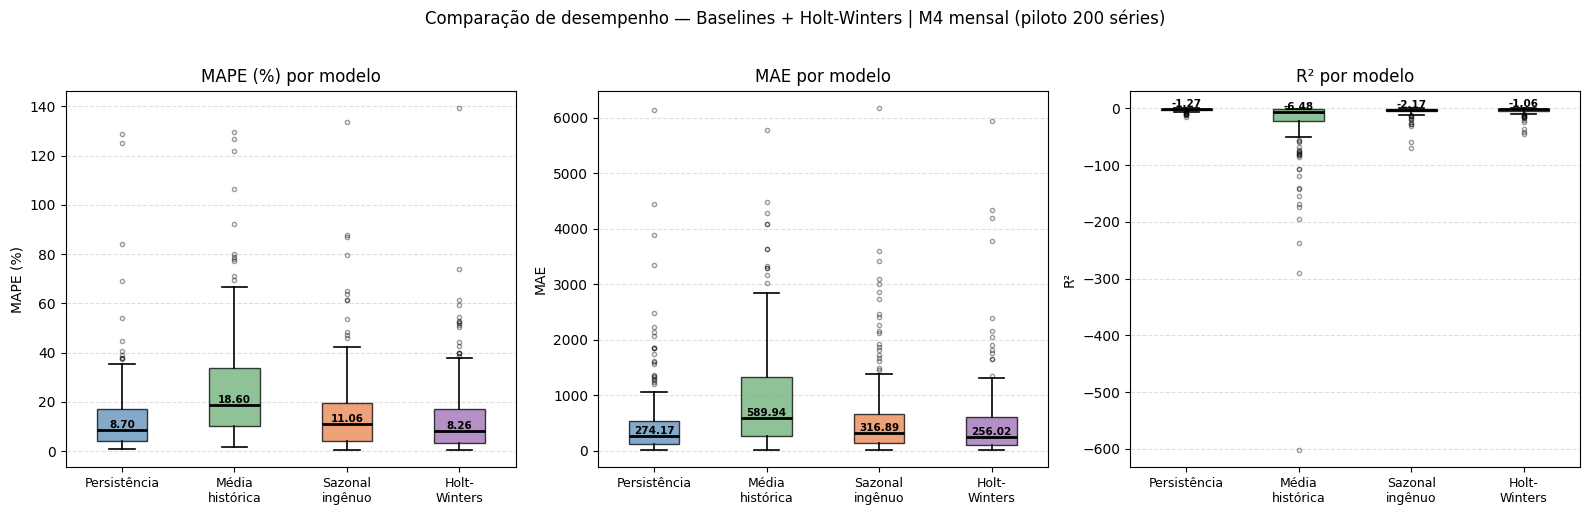

Figura salva em results/


In [16]:
order      = ['persistence', 'mean', 'seasonal_naive', 'holt_winters']
labels_pt  = ['Persistência', 'Média\nhistórica', 'Sazonal\ningênuo', 'Holt-\nWinters']
colors     = ['#5B8DB8', '#6BAE75', '#E8834E', '#9B6BB5']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, ylabel in zip(
    axes,
    ['mape', 'mae', 'r2'],
    ['MAPE (%)', 'MAE', 'R²']
):
    data_by_model = [
        by_series[by_series['model'] == m][metric].dropna()
        for m in order
    ]

    bp = ax.boxplot(
        data_by_model,
        patch_artist  = True,
        medianprops   = dict(color='black', linewidth=2),
        whiskerprops  = dict(linewidth=1.2),
        capprops      = dict(linewidth=1.2),
        flierprops    = dict(marker='o', markersize=3, alpha=0.4),
        showfliers    = True
    )
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_xticks(range(1, len(order)+1))
    ax.set_xticklabels(labels_pt, fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} por modelo')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    # Anotação da mediana
    for i, d in enumerate(data_by_model):
        ax.text(i+1, d.median(), f'{d.median():.2f}',
                ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.suptitle(
    'Comparação de desempenho — Baselines + Holt-Winters | M4 mensal (piloto 200 séries)',
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_boxplot_comparacao.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva em results/')

## 9. Gráfico 2 — Ganho relativo do Holt-Winters sobre os baselines

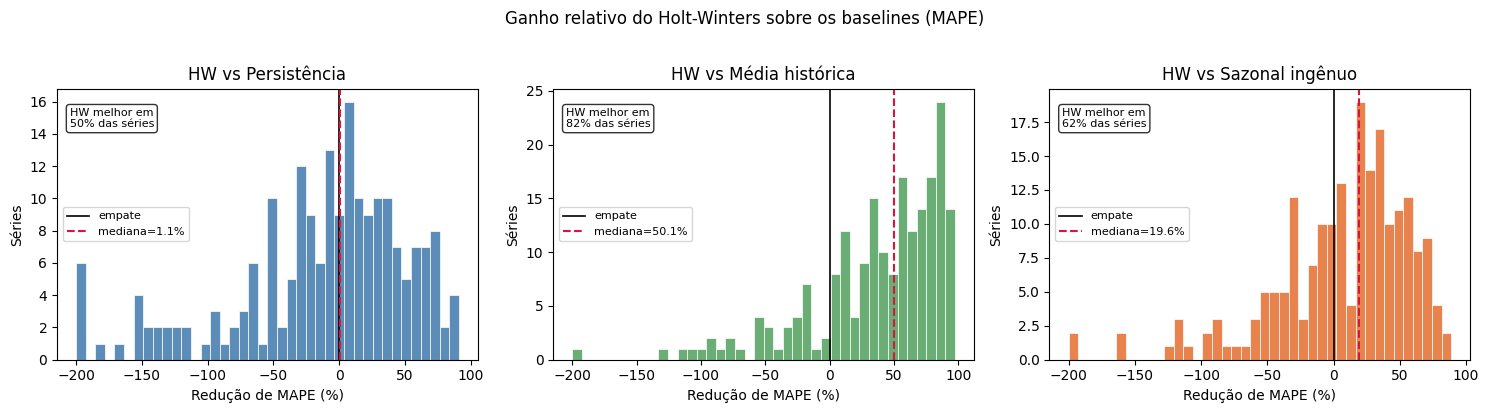

Figura salva em results/


In [17]:
# Para cada série, compara o MAPE do Holt-Winters com cada baseline
pivot = by_series.pivot(index='unique_id', columns='model', values='mape').dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

comparisons = [
    ('persistence',    'Persistência',      '#5B8DB8'),
    ('mean',           'Média histórica',   '#6BAE75'),
    ('seasonal_naive', 'Sazonal ingênuo',   '#E8834E'),
]

for ax, (baseline, label, color) in zip(axes, comparisons):
    if baseline not in pivot.columns or 'holt_winters' not in pivot.columns:
        ax.set_visible(False)
        continue

    # Redução percentual de MAPE: positivo = HW melhorou
    ganho = ((pivot[baseline] - pivot['holt_winters']) / pivot[baseline] * 100)
    ganho_clip = ganho.clip(-200, 100)   # limita para visualização

    ax.hist(ganho_clip, bins=40, color=color, edgecolor='white', linewidth=0.5)
    ax.axvline(0,              color='black',  linestyle='-',  linewidth=1.2, label='empate')
    ax.axvline(ganho.median(), color='crimson',linestyle='--', linewidth=1.5,
               label=f'mediana={ganho.median():.1f}%')
    ax.set_title(f'HW vs {label}')
    ax.set_xlabel('Redução de MAPE (%)')
    ax.set_ylabel('Séries')
    ax.legend(fontsize=8)

    pct_melhor = (ganho > 0).mean() * 100
    ax.text(0.03, 0.93, f'HW melhor em\n{pct_melhor:.0f}% das séries',
            transform=ax.transAxes, fontsize=8, va='top',
            bbox=dict(boxstyle='round', fc='white', alpha=0.8))

plt.suptitle('Ganho relativo do Holt-Winters sobre os baselines (MAPE)',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_ganho_holt_winters.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva em results/')

## 10. Gráfico 3 — Exemplo visual de uma série com os 4 modelos

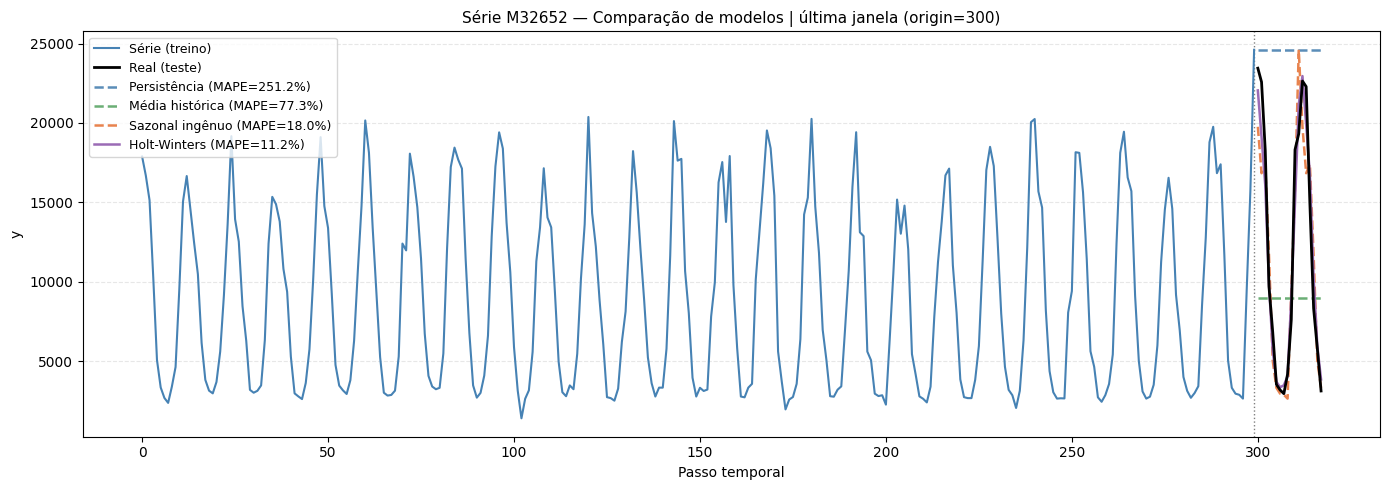

Série: M32652 | treino=300 obs | origem=300


In [18]:
# Seleciona a série onde o HW teve maior ganho sobre a persistência
if 'persistence' in pivot.columns and 'holt_winters' in pivot.columns:
    ganho_series = pivot['persistence'] - pivot['holt_winters']
    ex_uid = ganho_series.idxmax()
else:
    ex_uid = pilot_ids[0]

ex_vals = train_pilot[train_pilot['unique_id']==ex_uid]['y'].values.astype(float)
ex_wins = make_rolling_windows(ex_vals, H, MIN_TRAIN, N_ORIGINS)

# Usa a última janela para visualização
win = ex_wins[-1]

model_preds = {
    'Persistência'   : (baseline_persistence(win['train'], H),    '#5B8DB8', '--'),
    'Média histórica': (baseline_mean(win['train'], H),            '#6BAE75', '--'),
    'Sazonal ingênuo': (baseline_seasonal_naive(win['train'], H, SEASON), '#E8834E', '--'),
    'Holt-Winters'   : (holt_winters(win['train'], H, SEASON),    '#9B6BB5', '-'),
}

fig, ax = plt.subplots(figsize=(14, 5))

x_train = range(len(win['train']))
x_test  = range(len(win['train']), len(win['train']) + H)

ax.plot(x_train, win['train'], color='steelblue', linewidth=1.5,
        label='Série (treino)', zorder=5)
ax.plot(x_test, win['test'], color='black', linewidth=2,
        linestyle='-', label='Real (teste)', zorder=6)
ax.axvline(len(win['train'])-1, color='gray', linestyle=':', linewidth=1)

for label, (pred, color, ls) in model_preds.items():
    mape = calc_mape(win['test'], pred)
    ax.plot(x_test, pred, color=color, linewidth=1.8, linestyle=ls,
            label=f'{label} (MAPE={mape:.1f}%)')

ax.set_title(f'Série {ex_uid} — Comparação de modelos | última janela (origin={win["origin"]})',
             fontsize=11)
ax.set_xlabel('Passo temporal')
ax.set_ylabel('y')
ax.legend(fontsize=9, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / f'fig_exemplo_4modelos_{ex_uid}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Série: {ex_uid} | treino={len(win["train"])} obs | origem={win["origin"]}')

## 11. Salvando todos os artefatos

In [19]:
# CSV completo por janela
results_df.to_csv(RESULT_DIR / 'results_nb02_by_window.csv', index=False)

# CSV agregado por série
by_series.to_csv(RESULT_DIR / 'results_nb02_by_series.csv', index=False)

# Log de execução
run_log = {
    'timestamp'  : datetime.now().isoformat(),
    'notebook'   : '02_baselines_e_holt_winters',
    'dataset'    : 'M4_Monthly',
    'pilot_n'    : PILOT_N,
    'seed'       : SEED,
    'horizon_H'  : H,
    'min_train'  : MIN_TRAIN,
    'n_origins'  : N_ORIGINS,
    'models'     : [m for m, _ in models],
    'summary'    : summary.round(4).to_dict(),
}

with open(RESULT_DIR / 'run_log_nb02.json', 'w') as f:
    json.dump(run_log, f, indent=2, default=str)

print('Artefatos salvos em results/:')
for f in sorted(RESULT_DIR.glob('*nb02*')):
    print(f'  {f.name}')
print('  tabela_comparativa_baselines_hw.csv')
print('  fig_boxplot_comparacao.png')
print('  fig_ganho_holt_winters.png')
print(f'  fig_exemplo_4modelos_{ex_uid}.png')

Artefatos salvos em results/:
  results_nb02_by_series.csv
  results_nb02_by_window.csv
  run_log_nb02.json
  tabela_comparativa_baselines_hw.csv
  fig_boxplot_comparacao.png
  fig_ganho_holt_winters.png
  fig_exemplo_4modelos_M32652.png


## 12. Resumo interpretativo

---

| Modelo | Papel na dissertação |
|---|---|
| Persistência | Piso absoluto — o mais simples possível |
| Média histórica | Referência de nível central |
| Sazonal ingênuo | Teto dos baselines — captura o padrão sazonal sem parâmetros |
| **Holt-Winters** | **Primeiro modelo estatístico real — deve superar os 3 acima** |

---

### Interpretação esperada
- **MAPE**: Holt-Winters < Sazonal ingênuo < Persistência (menor = melhor)
- **R²**: Holt-Winters deve ser o único com R² próximo ou acima de zero
- **Tempo**: Holt-Winters é mais lento — custo do ajuste por otimização

---

### Próximo notebook: `03_sarima_ses.ipynb`
- **SES** — suavização exponencial simples (sem tendência/sazonalidade)
- **SARIMA** — modelo autorregressivo com sazonalidade explícita
- Comparação acumulada de 6 modelos